In [1]:
from arvpyf import mgmt, cf
from arvpyf.mgmt import ArchiverConfig
from arvpyf.cf import PVFinder
from arvpyf.ar import ArchiverReader
from pyCHX.chx_packages import *
import time
%matplotlib inline
import matplotlib.pyplot as plt

/nsls2/conda/envs/2024-2.0-py311-tiled/lib/python3.11/site-packages/databroker/v1.py:72: UserWarning: In databroker 2.x, there are separate notions of 'server' and 'client', and register_handler(...) has no effect on the client. Likely this is being done for you on the server side, so you should not worry about this message unless you encounter trouble loading large array data.
  warnings.warn(


## Setup for xf11id archives

In [2]:
import sys
sys.path.insert(0, "/nsls2/data/chx/shared/CHX_Software/packages/archiver_setup/")
sys.path.insert(0, "/nsls2/data/chx/shared/CHX_Software/packages/Auto_Analysis_Functions/")
from archiver_setup import *
from Auto_Analysis_Functions import *

%run /nsls2/data/chx/shared/CHX_Software/packages/environment_management/chx_analysis_setup.ipynb

successfully imported CHX channel archiver and related functions
running on: jupyter_hub   environment: standard

setting '_base_path_' as /nsls2/data/chx/legacy/analysis/
setting '_base_path_pass_' as /nsls2/data/chx/proposals/
setting '_mask_path_' as /nsls2/data/chx/shared/CHX_Setup/Detector_masks/

ran "%run -i /nsls2/data/chx/shared/CHX_Software/packages/patches/roi_nr_2019_3_0_1.py" to fix ROI numbering for PHI-sliced data sets. Should get fixed in pyCHX...
ran "%run -i /nsls2/data/chx/shared/CHX_Software/packages/patches/chx_outlier_detection.py": this should become part of pyCHX.
ran "%run -i /nsls2/data/chx/shared/CHX_Software/packages/patches/fix_get_sid_filenames.py": this should be fixed and re-deployed in pyCHX.

environment dependent settings and patches:
using "%matplotlib inline" for plotting
ran "%run -i /nsls2/data/chx/shared/CHX_Software/packages/patches/polygonmask_fix.py".
ran "%run -i /nsls2/data/chx/shared/CHX_Software/packages/pyCHX/backups/chx_compress_05012024

# get PVs by time-stamp from uid:
Warning: there might be a problem with time zones if NOT running on NSLS-II computing resources!

In [3]:
user = 'xmchen'
cycle = '2025_1'

scan = [165076]


##########################################################################################
uid_list = []; scan_list=[]
for s in scan:
    if type(s) == int:
        scan_list.append(s)
        uid=[h.start['uid'] for h in db(scan_id=s)][0]
        uid_list.append(uid)
    else:       
        h=db[s];uid_list.append(h.start['uid']);scan_list.append(h.start['scan_id'])
    h=db[uid_list[-1]]
    print('scan: %s -> uid: %s -> epoch [s]: %s'%(scan_list[-1],uid_list[-1],h.start['time']))

scan: 165076 -> uid: 9f544d84-8cac-4e0e-9ea3-d4e422809124 -> epoch [s]: 1740464759.5073142


In [43]:
uid = '9f544d84'
pv = 'XF:11IDB-ES{Env:02}LS340:TC1:Control'#'XF:11IDB-ES{Env:01-Chan:C}T-I'
pre=3600 #additional time included in the beginning [s]
post=3600 #additional time included in the end [s]
exact = time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(get_meta_data(uid)['time']))
since=time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(get_meta_data(uid)['time']-pre))
until=time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(get_meta_data(uid)['time']+post))

In [44]:
exact, since, until

('2025-02-25 01:25:59', '2025-02-25 00:25:59', '2025-02-25 02:25:59')

In [45]:
df = arvReader.get(pv, since, until)
dfS = arvReader.get(pv, exact, exact)

Text(0, 0.5, 'Temperature')

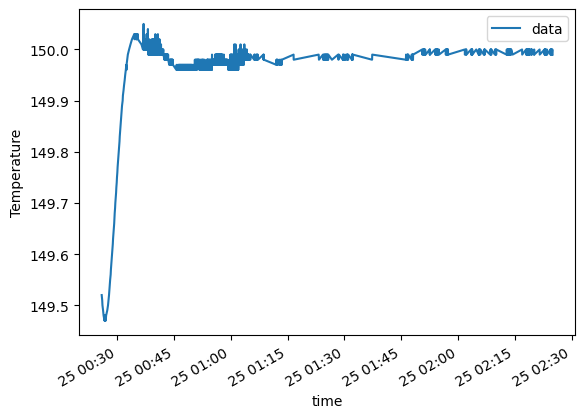

In [46]:
df.plot(x='time', y='data')
plt.ylabel('Temperature')
